In [1]:
import os

# os.environ["CUDA_VISIBLE_DEVICES"] = ""

In [2]:
import numpy as np

import torch
from torch import nn
from torch.nn import functional as F
torch.jit.script = lambda x: x

import re 
import h5py
from glob import glob
from functools import partial
from tqdm import tqdm

# from tensorflow.python.summary.summary_iterator import summary_iterator
# from tensorflow.compat.v1.train import summary_iterator
from tensorboard.backend.event_processing.event_file_loader import EventFileLoader

def summary_iterator(event_file):
    """
    流式读取 events 文件，逐条 yield event 对象。
    兼容原来 tensorflow.compat.v1.train.summary_iterator 的返回格式。
    """
    loader = EventFileLoader(event_file)
    for event in loader.Load():
        yield event

def get_scalar_value(v):
    if v.HasField('simple_value'):
        return v.simple_value
    elif v.HasField('tensor') and len(v.tensor.float_val) > 0:
        return v.tensor.float_val[0]
    return 0.0


from sklearn import metrics
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.metrics import accuracy_score, recall_score, precision_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from scipy.spatial.distance import pdist, cdist
from scipy import stats

from transformercvn.network.trainers.neutrino_full_dense_trainer import NeutrinoFullDenseTrainer, sparse_to_dense
from transformercvn.network.trainers.neutrino_full_sparse_trainer import NeutrinoFullSparseTrainer
from transformercvn.network.trainers.neutrino_full_sdxl_trainer import NeutrinoFullSDXLTrainer
from transformercvn.dataset.minkowski_dataset import MinkowskiCollection
from transformercvn.options import Options

from matplotlib import pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import cmasher as cmr
import seaborn as sb

# Training History

In [3]:
tags = ['lr-AdamW/pg1',  # Learning Rate
        'val_epoch_accuracy', 'event_epoch_accuracy', 'prong_epoch_accuracy', # Validation accuracy, val = (event + prong)/2
        'train_loss', 'train_event_accuracy', 'train_prong_accuracy', # Possibly not helpful with small batch size
        'val_epoch_AUC', 'event_epoch_AUC', 'prong_epoch_AUC'] # ROC AUC, average='weighted'

In [4]:
# Current 2026 training log:
# tensorboards = ['/home/binzhang/dune-transformercvn/training_2026prod/version_1/events.out.tfevents.1793822138.tau-neutrino.4024511.0']

# tensorboards = ['/home/binzhang/dune-transformercvn/tutorial_dense/version_4/events.out.tfevents.1786657984.tau-neutrino.1095849.0']

# tensorboards = ['/home/binzhang/dune-transformercvn/tutorial_dense/version_2/events.out.tfevents.1786489828.tau-neutrino.182851.0']

# tensorboards = ['/home/binzhang/dune-transformercvn/tutorial_dense/version_5/events.out.tfevents.1794965485.tau-neutrino.544403.0']

# tensorboards = ['/home/binzhang/dune-transformercvn/tutorial_dense/version_6/events.out.tfevents.1795029417.tau-neutrino.2406047.0']

# tensorboards = sorted(glob("./tutorial_dense/version_8/events.out.tfevents.*"))

# tensorboards = ['/home/binzhang/dune-transformercvn/tutorial_dense/version_8/events.out.tfevents.1795039324.tau-neutrino.2734728.0']

tensorboards = ['/home/binzhang/dune-transformercvn/training_2026prod/version_3/events.out.tfevents.1795137386.tau-neutrino.1359844.0']


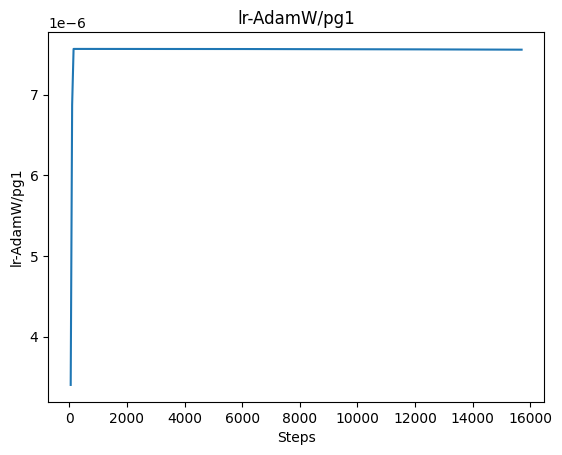

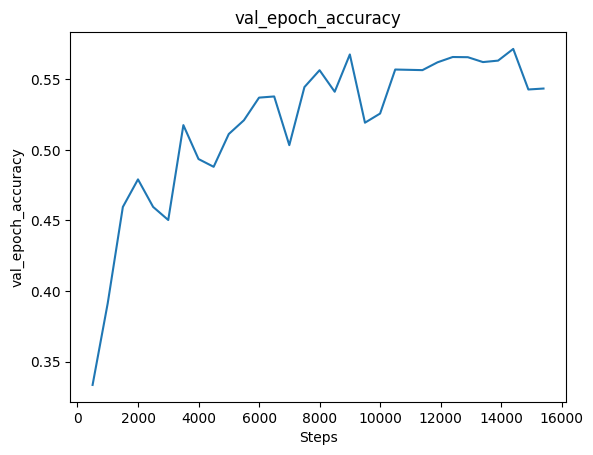

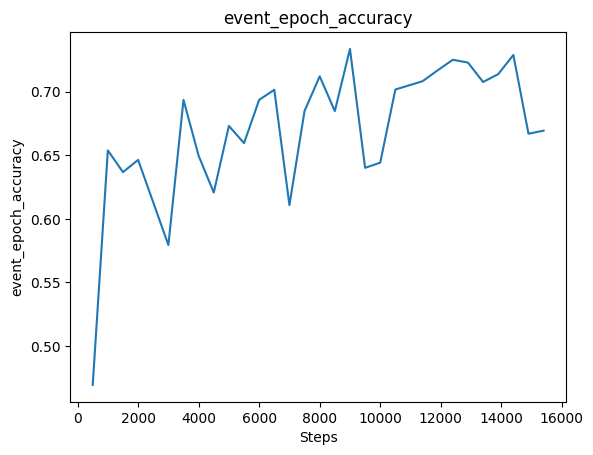

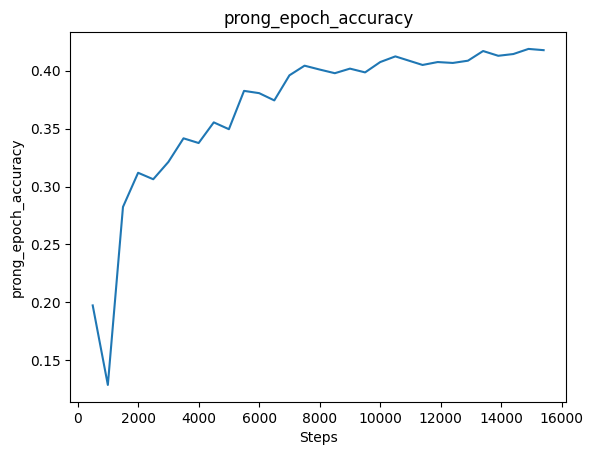

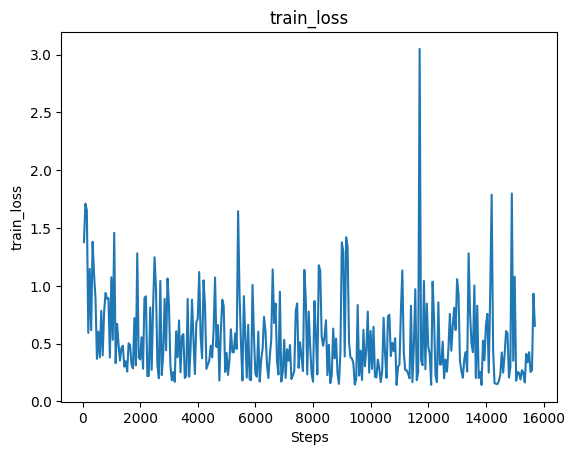

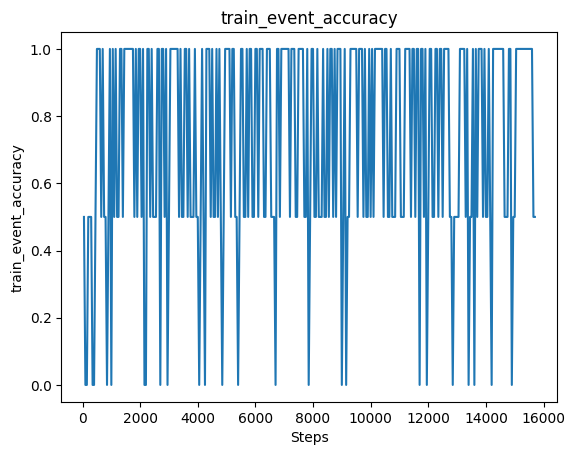

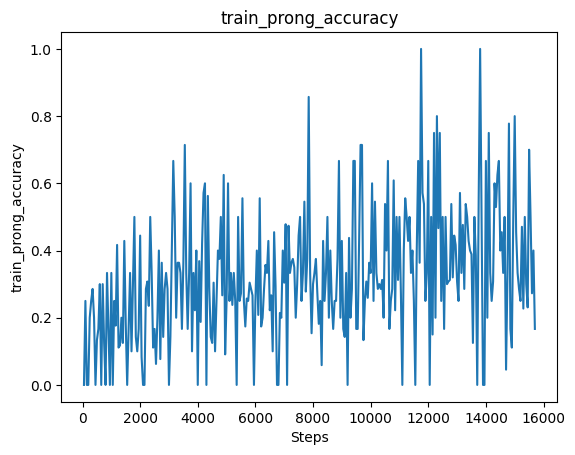

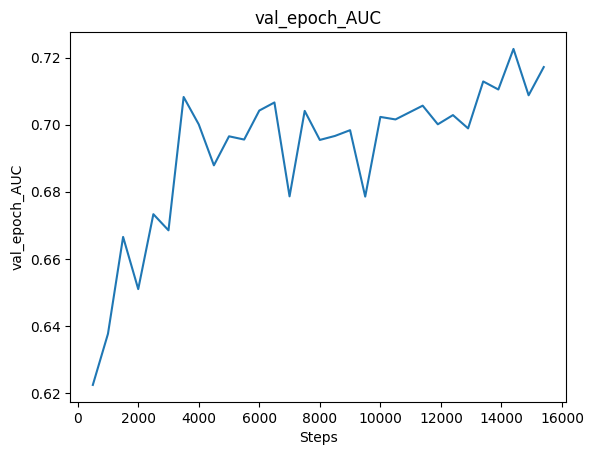

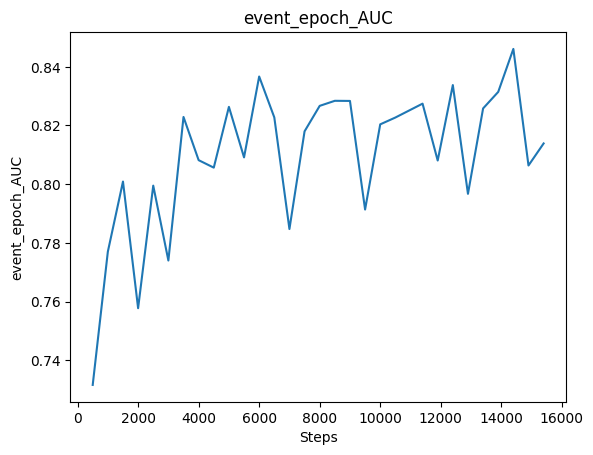

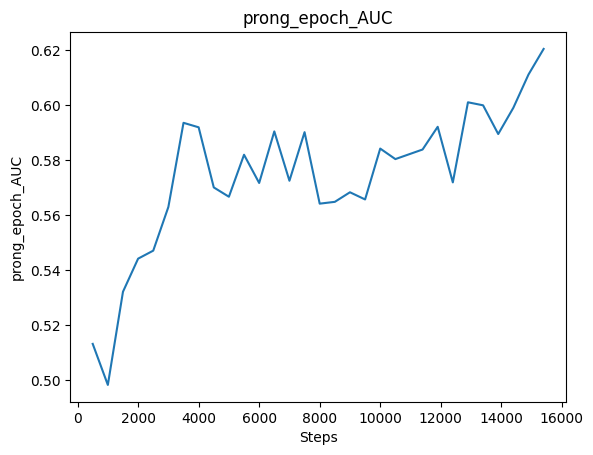

In [5]:
metrics = {tag:[] for tag in tags}

for tensorboard in tensorboards:
  for e in summary_iterator(tensorboard):
    for v in e.summary.value:
      #print(v)
      if v.tag in tags:
        val = get_scalar_value(v)
        metrics[v.tag].append([e.step, val])
#         metrics[v.tag].append([e.step, v.simple_value])
        last_step = e.step

for tag in tags:
    metric = np.array(metrics[tag])
    if metric.size==0:
        print("No values saved for metric", tag)
        continue
    plt.plot(metric[:,0], metric[:,1], label=tag)
    plt.xlabel('Steps')
    plt.ylabel(tag)
    plt.title(tag)
    #plt.legend()
    plt.show()

# Testing Dataset

In [6]:
CUDA = True
CUDA_DEVICE = 0
USE_TEX = False

#Specify a sperate testing file here if you have one. Otherwise, the validation dataset will be used.
TESTING_FILE = None

GRADIENT = False

NETWORK = NeutrinoFullSDXLTrainer
#NETWORK = NeutrinoFullDenseTrainer
#NETWORK = NeutrinoFullSDXLTrainer


In [7]:
# Current 2026 model and input (preserved for switching back):
# BASE_DIRECTORY = "./training_2026prod/version_1/"
# CHECKPOINT_PATH = "./training_2026prod/version_1/checkpoints/last.ckpt"
# Input: /home/binzhang/disk_binzhang/preprocessing_multi_production/Preprocessing_Alejandro/output_final/postprocessed_pixel_maps.h5

# BASE_DIRECTORY = "./tutorial_dense/version_4/"
# CHECKPOINT_PATH = "./tutorial_dense/version_4/checkpoints/last.ckpt"
# The input file is loaded from this run's options.json.

# BASE_DIRECTORY = "./tutorial_dense/version_2/"
# CHECKPOINT_PATH = "./tutorial_dense/version_2/checkpoints/last.ckpt"

# BASE_DIRECTORY = "./tutorial_dense/version_5/"
# CHECKPOINT_PATH = "./tutorial_dense/version_5/checkpoints/last.ckpt"

# BASE_DIRECTORY = "./tutorial_dense/version_6/"
# CHECKPOINT_PATH = "./tutorial_dense/version_6/checkpoints/last.ckpt"

# BASE_DIRECTORY = "./tutorial_dense/version_8/"
# CHECKPOINT_PATH = "./tutorial_dense/version_8/checkpoints/last.ckpt"

# BASE_DIRECTORY = "./tutorial_dense/version_8/"
# CHECKPOINT_PATH = "./tutorial_dense/version_8/checkpoints/last.ckpt"

BASE_DIRECTORY = "./training_2026prod/version_3/"
CHECKPOINT_PATH = "./training_2026prod/version_3/checkpoints/last.ckpt"


In [8]:
options = Options.load(f"{BASE_DIRECTORY}/options.json")
if TESTING_FILE:
    options.testing_file = TESTING_FILE
else:
    options.testing_file = options.training_file
options.num_dataloader_workers = 0

if CHECKPOINT_PATH is None:
    checkpoints = glob(f"{BASE_DIRECTORY}/checkpoints/epoch*.ckpt")
    last_checkpoint = np.argmax([int(re.search("step=(.*).ckpt", s)[1]) for s in checkpoints])
    checkpoint_path = checkpoints[last_checkpoint]
else:
    checkpoint_path = CHECKPOINT_PATH
checkpoint = torch.load(checkpoint_path, map_location='cpu')
state_dict = checkpoint["state_dict"]
print(f"Loading from: {checkpoint_path}")

network = NETWORK(options)
network.load_state_dict(state_dict)

network = network.eval()

if not GRADIENT:
    for parameter in network.parameters():
        parameter.requires_grad_(False)

if CUDA:
    network = network.cuda(CUDA_DEVICE)

Loading from: ./training_2026prod/version_3/checkpoints/last.ckpt


In [9]:
# Use the specified testing file, or the validation split saved with this run.
if TESTING_FILE:
    DATASET = network.testing_dataset
else:
    DATASET = network.validation_dataset


In [10]:
np.bincount(DATASET.event_targets)

array([4011, 6991, 3510,   21])

In [11]:
dataloader_options = network.dataloader_options
dataloader_options["pin_memory"] = False
dataloader_options["num_workers"] = 0
dataloader_options["batch_size"] = 16
dataloader_options["drop_last"] = False

test_dataloader = network.dataloader(DATASET, **dataloader_options)

In [12]:
batch = next(iter(network.dataloader(DATASET, **dataloader_options)))

if CUDA:
    batch = [b.cuda(CUDA_DEVICE) for b in batch]

(
        features,
        extra,
        event_coordinates,
        event_pixel_values,
        event_masks,
        prong_coordinates,
        prong_pixel_values,
        prong_masks,
        event_target,
        prong_target
) = batch

event_logits, prong_logits = network.forward(
        features,
        extra,
        event_coordinates,
        event_pixel_values,
        event_masks,
        prong_coordinates,
        prong_pixel_values,
        prong_masks,
    )

In [13]:
event_predictions = []
prong_predictions = []

event_targets = []
prong_targets = []

event_raws = []
prong_raws = []

total_attentions = []

for batch_idx, batch in enumerate(tqdm(test_dataloader)):
    if CUDA:
        batch = [b.cuda(CUDA_DEVICE) for b in batch]
        
    (
            features,
            extra,
            event_coordinates,
            event_pixel_values,
            event_masks,
            prong_coordinates,
            prong_pixel_values,
            prong_masks,
            event_target,
            prong_target
    ) = batch
    
    event_logits, prong_logits = network.forward(
            features,
            extra,
            event_coordinates,
            event_pixel_values,
            event_masks,
            prong_coordinates,
            prong_pixel_values,
            prong_masks,
        )
    
    event_predictions.append(event_logits.argmax(-1).cpu())
    prong_predictions.append(prong_logits.argmax(-1).cpu())
    
    event_targets.append(event_target.cpu())
    prong_targets.append(prong_target.cpu())
    
    event_raws.append(event_logits.cpu())
    prong_raws.append(prong_logits.cpu())
            
event_targets = torch.cat(event_targets)
prong_targets = torch.cat(prong_targets)

event_predictions = torch.cat(event_predictions)
prong_predictions = torch.cat(prong_predictions)

event_raws = torch.cat(event_raws)
prong_raws = torch.cat(prong_raws)

prong_mask = prong_targets >= 0

  0%|          | 0/909 [00:00<?, ?it/s]

  0%|          | 1/909 [00:00<10:39,  1.42it/s]

  0%|          | 2/909 [00:01<13:40,  1.11it/s]

  0%|          | 3/909 [00:03<17:25,  1.15s/it]

  0%|          | 4/909 [00:03<15:13,  1.01s/it]

  1%|          | 5/909 [00:05<17:26,  1.16s/it]

... (901 outputs left out)

100%|█████████▉| 907/909 [16:05<00:02,  1.10s/it]

100%|█████████▉| 908/909 [16:06<00:01,  1.05s/it]

100%|██████████| 909/909 [16:06<00:00,  1.28it/s]

100%|██████████| 909/909 [16:06<00:00,  1.06s/it]

In [14]:
event_probabilities = torch.softmax(event_raws, dim=1)
prong_probabilities = torch.softmax(prong_raws, dim=2)

In [15]:
flat_prong_probabilities = prong_probabilities[prong_mask]
flat_prong_predictions = prong_predictions[prong_mask]
flat_prong_targets = prong_targets[prong_mask]

In [16]:
event_probabilities # Score for [NumuCC, NueCC, NC, Other]

tensor([[0.1181, 0.7122, 0.1667, 0.0030],
        [0.8131, 0.0412, 0.1388, 0.0069],
        [0.7161, 0.0686, 0.2136, 0.0018],
        ...,
        [0.1162, 0.5772, 0.3040, 0.0026],
        [0.3438, 0.0959, 0.5573, 0.0030],
        [0.3324, 0.1307, 0.5339, 0.0030]])

In [17]:
event_targets

tensor([2, 0, 2,  ..., 1, 1, 1])

In [18]:
prong_probabilities # Score for [Electron, Muon, Proton, Neutron,
                    #            Pi +/-, Pi0, Photon, Other]

tensor([[[0.2012, 0.1682, 0.1045,  ..., 0.0743, 0.0722, 0.1075],
         [0.1828, 0.1032, 0.1745,  ..., 0.1100, 0.0884, 0.1061],
         [0.0874, 0.1162, 0.0797,  ..., 0.1216, 0.1777, 0.0977],
         ...,
         [0.0874, 0.1162, 0.0797,  ..., 0.1216, 0.1777, 0.0977],
         [0.0874, 0.1162, 0.0797,  ..., 0.1216, 0.1777, 0.0977],
         [0.0874, 0.1162, 0.0797,  ..., 0.1216, 0.1777, 0.0977]],

        [[0.0429, 0.5169, 0.0643,  ..., 0.0542, 0.0159, 0.0978],
         [0.0795, 0.1150, 0.2747,  ..., 0.1304, 0.0908, 0.1149],
         [0.0804, 0.1113, 0.2797,  ..., 0.1360, 0.0895, 0.1126],
         ...,
         [0.0874, 0.1162, 0.0797,  ..., 0.1216, 0.1777, 0.0977],
         [0.0874, 0.1162, 0.0797,  ..., 0.1216, 0.1777, 0.0977],
         [0.0874, 0.1162, 0.0797,  ..., 0.1216, 0.1777, 0.0977]],

        [[0.1370, 0.1567, 0.1251,  ..., 0.0835, 0.0992, 0.1307],
         [0.0666, 0.1050, 0.4071,  ..., 0.0702, 0.0622, 0.1196],
         [0.0675, 0.1053, 0.4007,  ..., 0.0771, 0.0623, 0.

In [19]:
prong_targets

tensor([[ 5,  5, -1,  ..., -1, -1, -1],
        [ 1,  4,  4,  ..., -1, -1, -1],
        [ 4,  2,  2,  ..., -1, -1, -1],
        ...,
        [ 0,  0, -1,  ..., -1, -1, -1],
        [ 5,  2, -1,  ..., -1, -1, -1],
        [ 2, -1, -1,  ..., -1, -1, -1]], dtype=torch.int8)

In [20]:
with h5py.File(BASE_DIRECTORY+"eval_predictions.h5", "w") as file:
    file.create_dataset("event_probabilities", data=event_probabilities.numpy())
    file.create_dataset("event_predictions", data=event_predictions.numpy())
    file.create_dataset("event_targets", data=event_targets.numpy())
    
    file.create_dataset("prong_probabilities", data=prong_probabilities.numpy())
    file.create_dataset("prong_predictions", data=prong_predictions.numpy())
    file.create_dataset("prong_targets", data=prong_targets.numpy())

# Testing Metrics

In [21]:
event_classes = ["NumuCC", "NueCC", "NC", "Other"]
prong_classes = ["Electron", "Muon", "Proton", "Neutron", "Pi+/-", "Pi0", "Photon", "Other"]
prong_classes_5class = ["Electron", "Muon", "Proton", "Pi+/-", "Pi0/Photon"]

In [22]:
print("Event Target Shape: ", event_targets.shape)
print("Event Probability Shape: ", event_probabilities.shape)
print("Prong Target Shape: ", flat_prong_targets.shape)
print("Prong Probability Shape: ", flat_prong_probabilities.shape)

print()

print(f"Event Accuracy: {accuracy_score(event_targets, event_predictions):.3f}")
print(f"Event Precision: {precision_score(event_targets, event_predictions, average='weighted'):.3f}")
print(f"Event Recall: {recall_score(event_targets, event_predictions, average='weighted'):.3f}")
print(f"Event ROC AUC: {roc_auc_score(event_targets, event_probabilities, multi_class='ovr', average='weighted'):.3f}")

print()

print(f"Prong Accuracy: {accuracy_score(flat_prong_targets, flat_prong_predictions):.3f}")
print(f"Prong Precision: {precision_score(flat_prong_targets, flat_prong_predictions, average='weighted'):.3f}")
print(f"Prong Recall: {recall_score(flat_prong_targets, flat_prong_predictions, average='weighted'):.3f}")
print(f"Prong ROC AUC: {roc_auc_score(flat_prong_targets, flat_prong_probabilities, multi_class='ovr', average='weighted'):.3f}")

Event Target Shape:  torch.Size([14533])
Event Probability Shape:  torch.Size([14533, 4])
Prong Target Shape:  torch.Size([67328])
Prong Probability Shape:  torch.Size([67328, 8])

Event Accuracy: 0.683
Event Precision: 0.724
Event Recall: 0.683
Event ROC AUC: 0.880

Prong Accuracy: 0.417
Prong Precision: 0.287
Prong Recall: 0.417


/mnt/ironwolf_14t2/users/binzhang/local/transformercvn-repro-from-yml/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/mnt/ironwolf_14t2/users/binzhang/local/transformercvn-repro-from-yml/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


Prong ROC AUC: 0.670


In [23]:
# Check event classification performance
event_aucs = roc_auc_score(
    event_targets.numpy(),
    event_probabilities.numpy(),
    average=None,
    multi_class="ovr"
)

print(f"NumuCC ROC AUC: {event_aucs[0]:.3f}")
print(f"NueCC ROC AUC: {event_aucs[1]:.3f}")
print(f"NC ROC AUC: {event_aucs[2]:.3f}")
print(f"Other AUC: {event_aucs[3]:.3f}")

NumuCC ROC AUC: 0.909
NueCC ROC AUC: 0.890
NC ROC AUC: 0.828
Other AUC: 0.675


In [24]:
# Check prong classification performance
prong_aucs = roc_auc_score(
    flat_prong_targets.numpy(),
    flat_prong_probabilities.numpy(),
    average=None,
    multi_class="ovr"
)

print(f"Electron ROC AUC: {prong_aucs[0]:.3f}")
print(f"Muon ROC AUC: {prong_aucs[1]:.3f}")
print(f"Proton ROC AUC: {prong_aucs[2]:.3f}")
print(f"Neutron AUC: {prong_aucs[3]:.3f}")
print(f"Charged Pion ROC AUC: {prong_aucs[4]:.3f}")
print(f"Neutral Pion ROC AUC: {prong_aucs[5]:.3f}")
print(f"Photon ROC AUC: {prong_aucs[6]:.3f}")
print(f"Other AUC: {prong_aucs[7]:.3f}")

Electron ROC AUC: 0.768
Muon ROC AUC: 0.856
Proton ROC AUC: 0.683
Neutron AUC: 0.393
Charged Pion ROC AUC: 0.497
Neutral Pion ROC AUC: 0.669
Photon ROC AUC: 0.521
Other AUC: 0.524


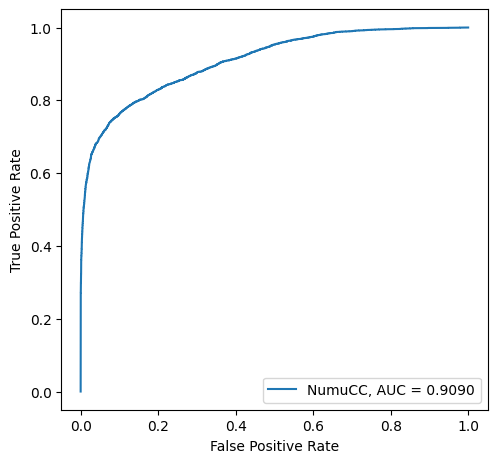

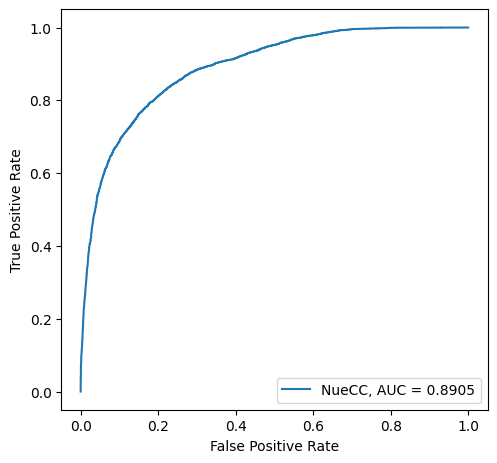

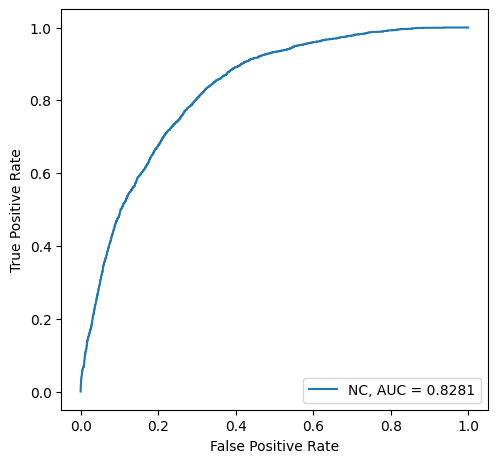

In [25]:
for i in range(3):
    plt.figure(figsize=[5.5,5.2])
    fpr,tpr,thr = roc_curve(event_targets, event_probabilities[:,i], pos_label=i, drop_intermediate=False)
    plt.plot(fpr,tpr, label = ("%s, AUC = %.4f" % (event_classes[i], event_aucs[i]) if "event_aucs" in globals() else event_classes[i]))
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(loc='lower right')

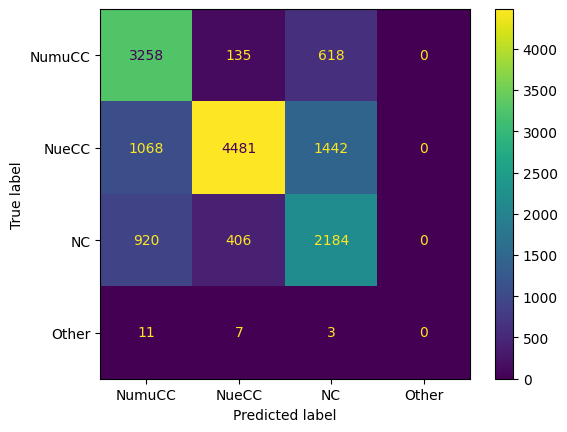

In [26]:
err_mat = confusion_matrix(event_targets, event_predictions, labels=np.arange(len(event_classes)))
disp = ConfusionMatrixDisplay(confusion_matrix=err_mat, display_labels=event_classes)
disp.plot()

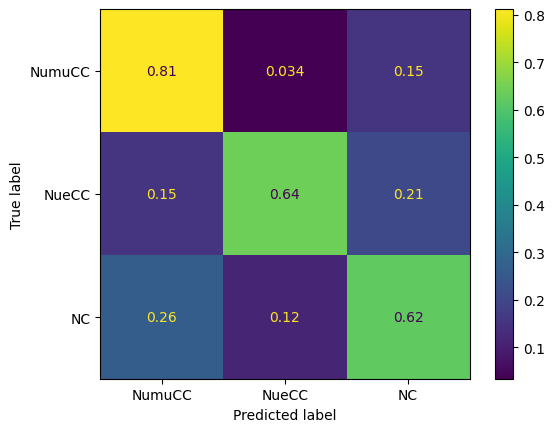

In [27]:
err_mat = confusion_matrix(event_targets, event_predictions, normalize='true', labels=[0,1,2])
disp = ConfusionMatrixDisplay(confusion_matrix=err_mat, display_labels=event_classes[:3])
disp.plot()

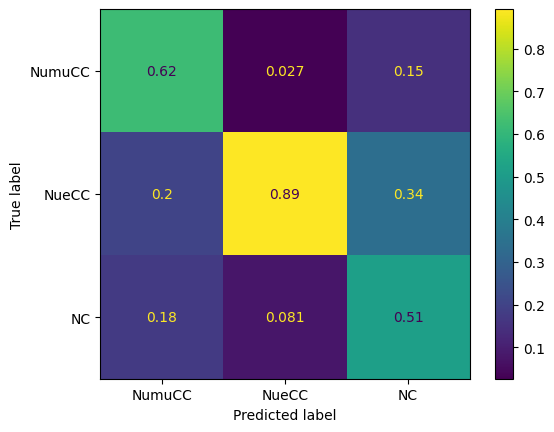

In [28]:
err_mat = confusion_matrix(event_targets, event_predictions, normalize='pred', labels=[0,1,2])
disp = ConfusionMatrixDisplay(confusion_matrix=err_mat, display_labels=event_classes[:3])
disp.plot()

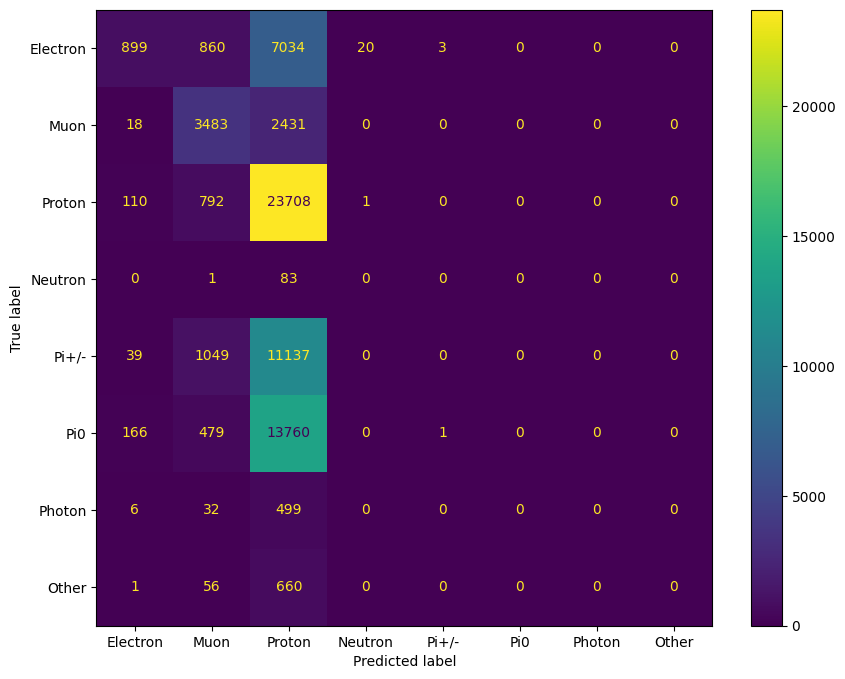

In [29]:
# "Neutron" and "Pi0" indicate photons from mother neutron/Pi0
# "Photon" indicates all other photons
err_mat = confusion_matrix(flat_prong_targets, flat_prong_predictions, labels=np.arange(len(prong_classes)))
disp = ConfusionMatrixDisplay(confusion_matrix=err_mat, display_labels=prong_classes)
fig,ax=plt.subplots(figsize=[10,8])
disp.plot(ax=ax)

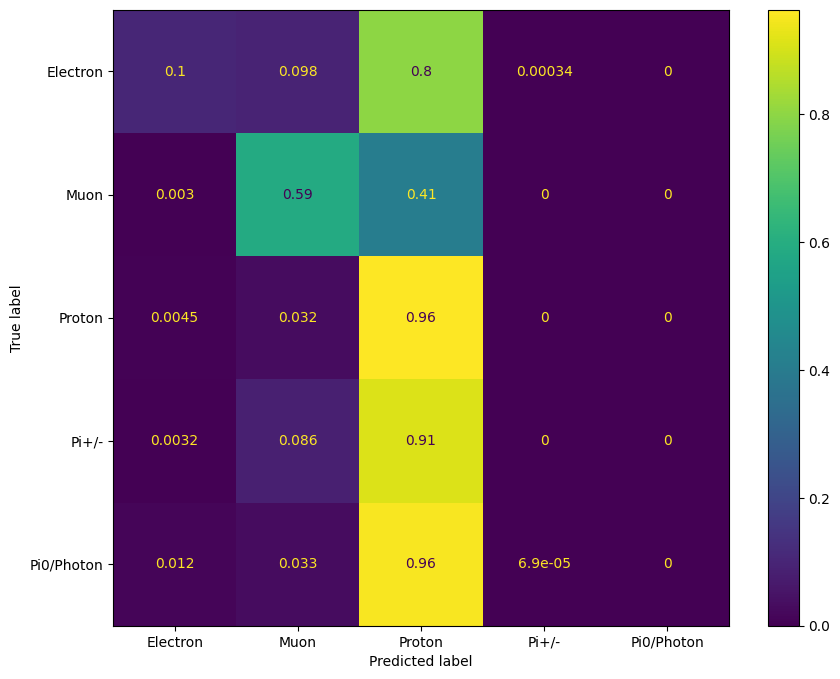

In [30]:
err_mat = confusion_matrix(flat_prong_targets, flat_prong_predictions, normalize='true', labels=[0,1,2,4,5])
disp = ConfusionMatrixDisplay(confusion_matrix=err_mat, display_labels=prong_classes_5class)
fig,ax=plt.subplots(figsize=[10,8])
disp.plot(ax=ax)

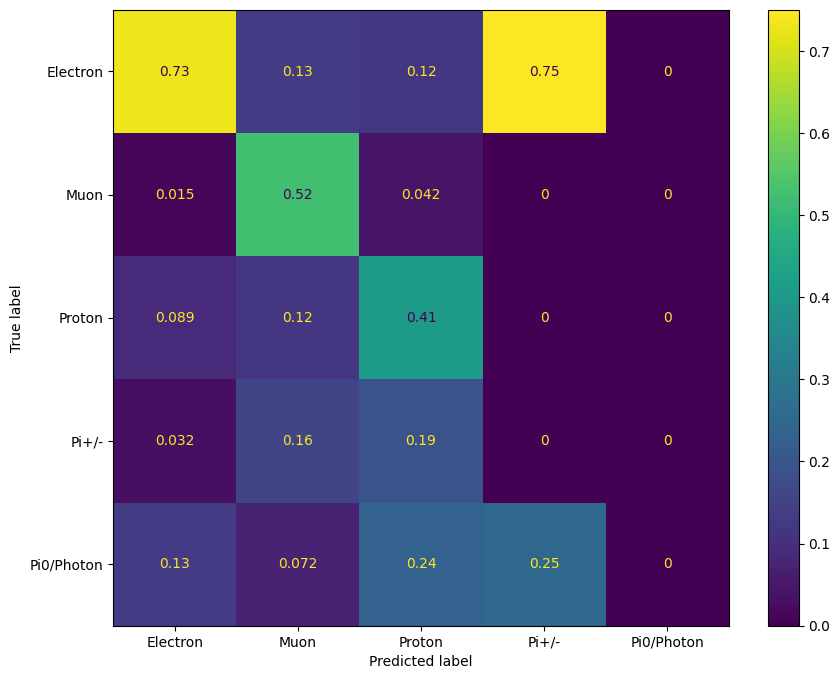

In [31]:
err_mat = confusion_matrix(flat_prong_targets, flat_prong_predictions, normalize='pred', labels=[0,1,2,4,5])
disp = ConfusionMatrixDisplay(confusion_matrix=err_mat, display_labels=prong_classes_5class)
fig,ax=plt.subplots(figsize=[10,8])
disp.plot(ax=ax)

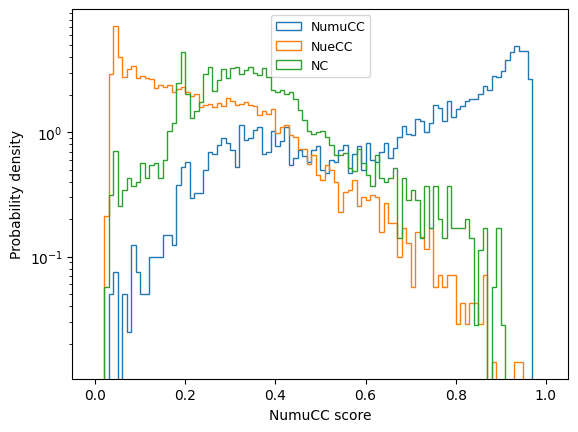

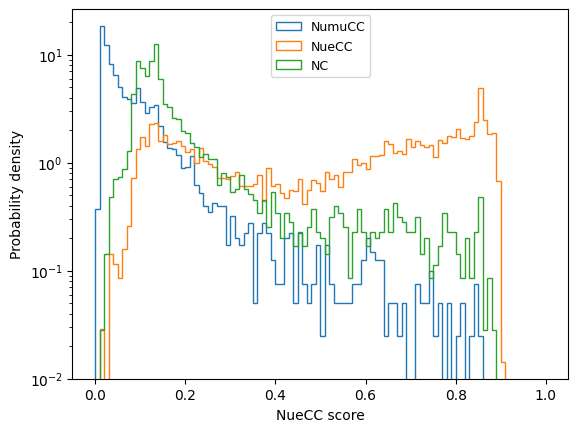

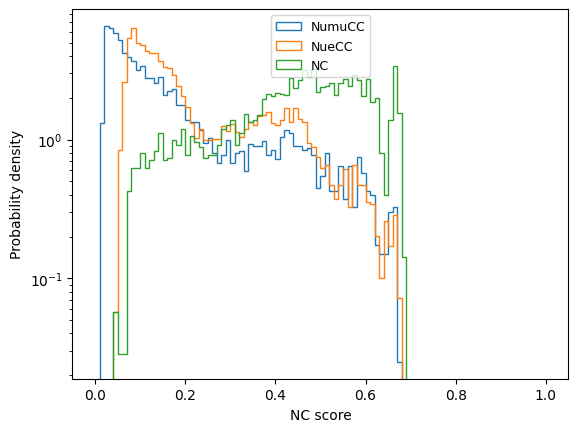

In [32]:
scores = event_probabilities.cpu().numpy()
true_labels = event_targets.cpu().numpy()
bins = np.arange(0, 1.01, 0.01)

for score_class in range(3):
    fig, ax = plt.subplots()
    for true_class in range(3):
        selected_scores = scores[true_labels == true_class, score_class]
        if selected_scores.size:
            ax.hist(selected_scores, bins=bins, histtype="step",
                    label=event_classes[true_class], density=True)
    ax.legend(loc="upper center", fontsize=9)
    ax.set_yscale("log")
    ax.set_xlabel(event_classes[score_class] + " score")
    ax.set_ylabel("Probability density")
    plt.show()
    plt.close(fig)


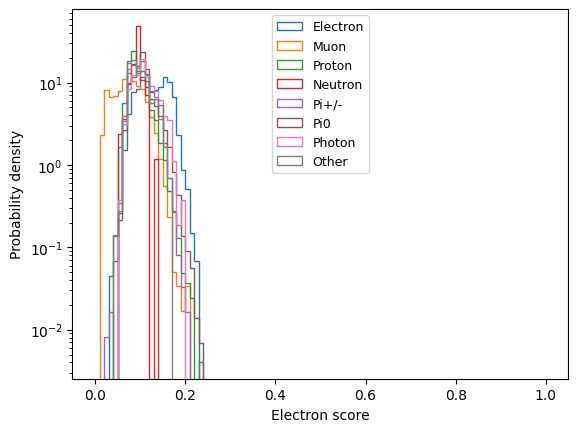

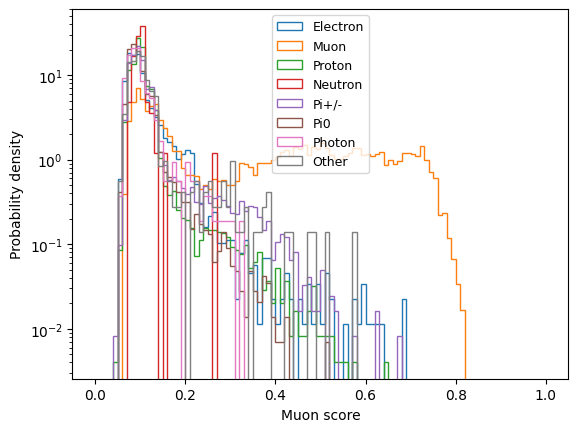

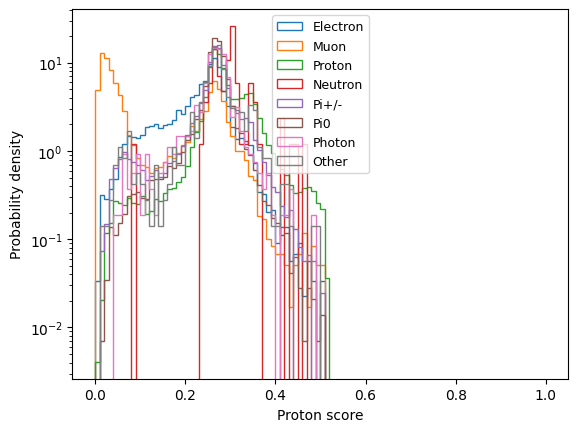

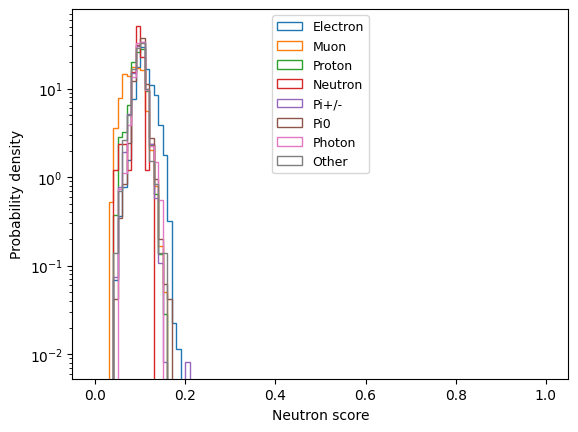

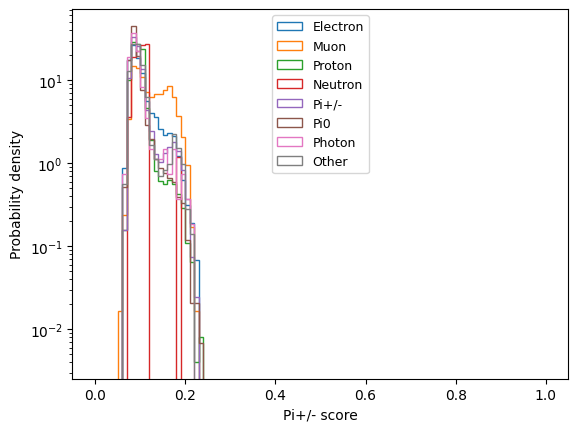

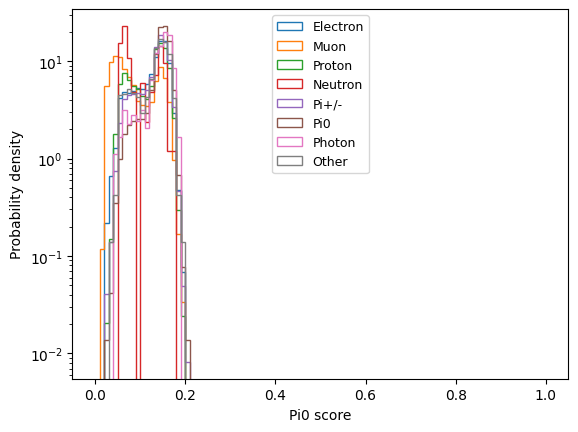

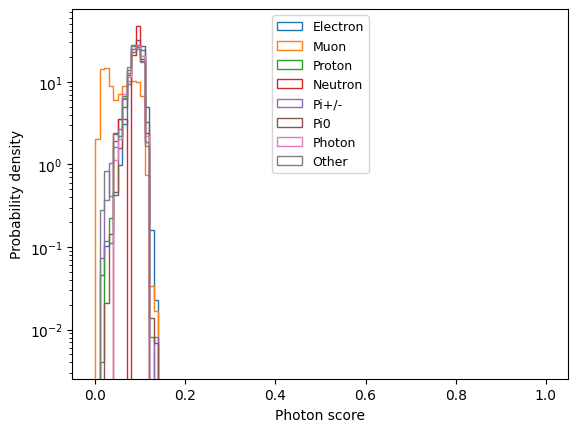

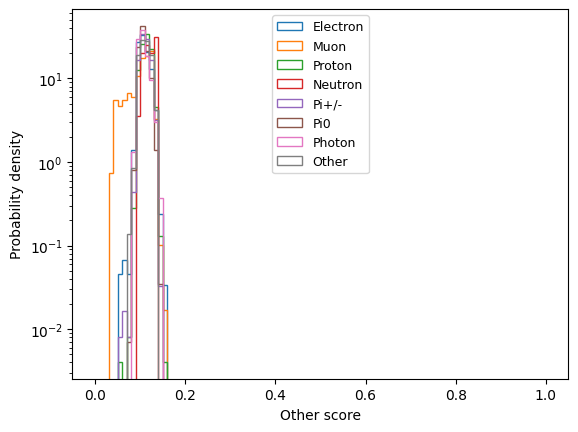

In [33]:
scores = flat_prong_probabilities.cpu().numpy()
true_labels = flat_prong_targets.cpu().numpy()
bins = np.arange(0, 1.01, 0.01)

for score_class in range(8):
    fig, ax = plt.subplots()
    for true_class in range(8):
        selected_scores = scores[true_labels == true_class, score_class]
        if selected_scores.size:
            ax.hist(selected_scores, bins=bins, histtype="step",
                    label=prong_classes[true_class], density=True)
    ax.legend(loc="upper center", fontsize=9)
    ax.set_yscale("log")
    ax.set_xlabel(prong_classes[score_class] + " score")
    ax.set_ylabel("Probability density")
    plt.show()
    plt.close(fig)
